In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
train_path = "../data/train_FD001.txt"

train = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None
)

print("Dataset shape:", train.shape)

Dataset shape: (20631, 26)


In [3]:
columns = (
    ["engine_id", "cycle",
     "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train.columns = columns

print(train.head())

   engine_id  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  \
0          1      1    -0.0007    -0.0004      100.0    518.67    641.82   
1          1      2     0.0019    -0.0003      100.0    518.67    642.15   
2          1      3    -0.0043     0.0003      100.0    518.67    642.35   
3          1      4     0.0007     0.0000      100.0    518.67    642.35   
4          1      5    -0.0019    -0.0002      100.0    518.67    642.37   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1589.70   1400.60     14.62  ...     521.66    2388.02    8138.62   
1   1591.82   1403.14     14.62  ...     522.28    2388.07    8131.49   
2   1587.99   1404.20     14.62  ...     522.42    2388.03    8133.23   
3   1582.79   1401.87     14.62  ...     522.86    2388.08    8133.83   
4   1582.85   1406.22     14.62  ...     522.19    2388.04    8133.80   

   sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21  
0     8.4195       0.03

In [4]:
print(train.info())

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor_16  20631 

In [5]:
print(train.describe())


          engine_id         cycle     setting_1     setting_2  setting_3  \
count  20631.000000  20631.000000  20631.000000  20631.000000    20631.0   
mean      51.506568    108.807862     -0.000009      0.000002      100.0   
std       29.227633     68.880990      0.002187      0.000293        0.0   
min        1.000000      1.000000     -0.008700     -0.000600      100.0   
25%       26.000000     52.000000     -0.001500     -0.000200      100.0   
50%       52.000000    104.000000      0.000000      0.000000      100.0   
75%       77.000000    156.000000      0.001500      0.000300      100.0   
max      100.000000    362.000000      0.008700      0.000600      100.0   

       sensor_1      sensor_2      sensor_3      sensor_4      sensor_5  ...  \
count  20631.00  20631.000000  20631.000000  20631.000000  2.063100e+04  ...   
mean     518.67    642.680934   1590.523119   1408.933782  1.462000e+01  ...   
std        0.00      0.500053      6.131150      9.000605  5.329200e-15  ..

In [6]:
print("Number of engines:", train["engine_id"].nunique())
print("Number of sensors:", len([c for c in train.columns if c.startswith("sensor_")]))

Number of engines: 100
Number of sensors: 21


In [7]:
sensor_columns = [c for c in train.columns if c.startswith("sensor_")]


In [8]:
sensor_stats = train[sensor_columns].describe().T

print(sensor_stats[["mean", "std", "min", "max"]])

                  mean           std        min        max
sensor_1    518.670000  0.000000e+00   518.6700   518.6700
sensor_2    642.680934  5.000533e-01   641.2100   644.5300
sensor_3   1590.523119  6.131150e+00  1571.0400  1616.9100
sensor_4   1408.933782  9.000605e+00  1382.2500  1441.4900
sensor_5     14.620000  5.329200e-15    14.6200    14.6200
sensor_6     21.609803  1.388985e-03    21.6000    21.6100
sensor_7    553.367711  8.850923e-01   549.8500   556.0600
sensor_8   2388.096652  7.098548e-02  2387.9000  2388.5600
sensor_9   9065.242941  2.208288e+01  9021.7300  9244.5900
sensor_10     1.300000  0.000000e+00     1.3000     1.3000
sensor_11    47.541168  2.670874e-01    46.8500    48.5300
sensor_12   521.413470  7.375534e-01   518.6900   523.3800
sensor_13  2388.096152  7.191892e-02  2387.8800  2388.5600
sensor_14  8143.752722  1.907618e+01  8099.9400  8293.7200
sensor_15     8.442146  3.750504e-02     8.3249     8.5848
sensor_16     0.030000  3.469531e-18     0.0300     0.03

In [9]:
low_variance = sensor_stats[sensor_stats["std"] < 0.1]

print("Nearly constant sensors:")
print(low_variance[["std"]])

Nearly constant sensors:
                    std
sensor_1   0.000000e+00
sensor_5   5.329200e-15
sensor_6   1.388985e-03
sensor_8   7.098548e-02
sensor_10  0.000000e+00
sensor_13  7.191892e-02
sensor_15  3.750504e-02
sensor_16  3.469531e-18
sensor_18  0.000000e+00
sensor_19  0.000000e+00


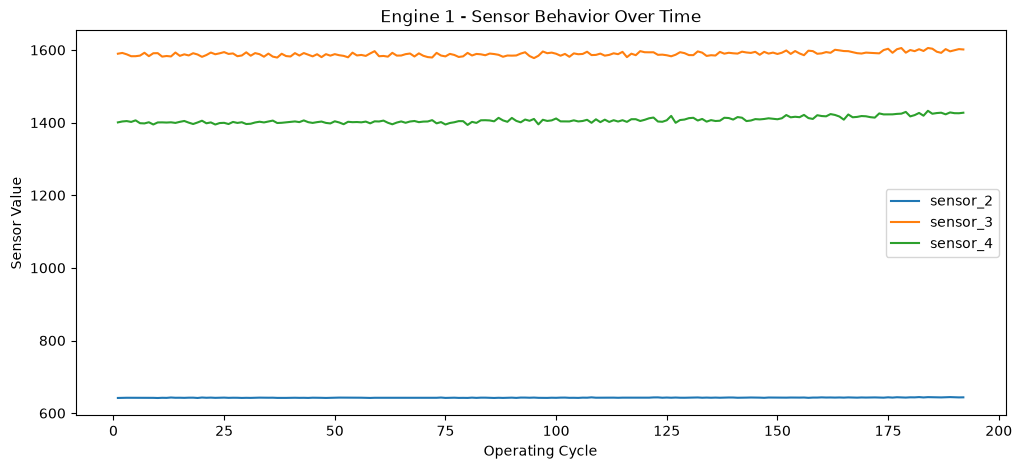

In [10]:
engine_1 = train[train["engine_id"] == 1]

plt.figure(figsize=(12, 5))

for sensor in ["sensor_2", "sensor_3", "sensor_4"]:
    plt.plot(
        engine_1["cycle"],
        engine_1[sensor],
        label=sensor
    )

plt.xlabel("Operating Cycle")
plt.ylabel("Sensor Value")
plt.title("Engine 1 - Sensor Behavior Over Time")
plt.legend()
plt.show()


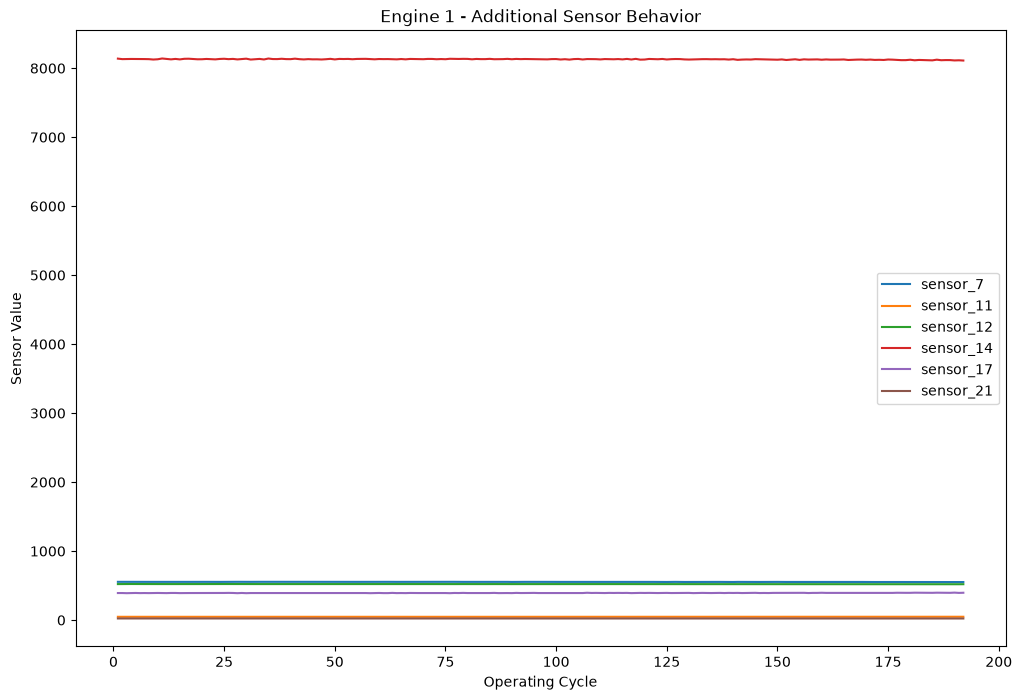

In [11]:
selected_sensors = [
    "sensor_7",
    "sensor_11",
    "sensor_12",
    "sensor_14",
    "sensor_17",
    "sensor_21"
]

plt.figure(figsize=(12, 8))

for sensor in selected_sensors:
    plt.plot(
        engine_1["cycle"],
        engine_1[sensor],
        label=sensor
    )

plt.xlabel("Operating Cycle")
plt.ylabel("Sensor Value")
plt.title("Engine 1 - Additional Sensor Behavior")
plt.legend()
plt.show()


In [12]:
max_cycles = train.groupby("engine_id")["cycle"].max()

train["RUL"] = train.apply(
    lambda row: max_cycles[row["engine_id"]] - row["cycle"],
    axis=1
)

print(train[["engine_id", "cycle", "RUL"]].head(10))

   engine_id  cycle    RUL
0          1      1  191.0
1          1      2  190.0
2          1      3  189.0
3          1      4  188.0
4          1      5  187.0
5          1      6  186.0
6          1      7  185.0
7          1      8  184.0
8          1      9  183.0
9          1     10  182.0


In [13]:
print(train["RUL"].describe())

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64


In [14]:
print(train.groupby("engine_id")["RUL"].agg(["min", "max"]).head())


           min    max
engine_id            
1          0.0  191.0
2          0.0  286.0
3          0.0  178.0
4          0.0  188.0
5          0.0  268.0


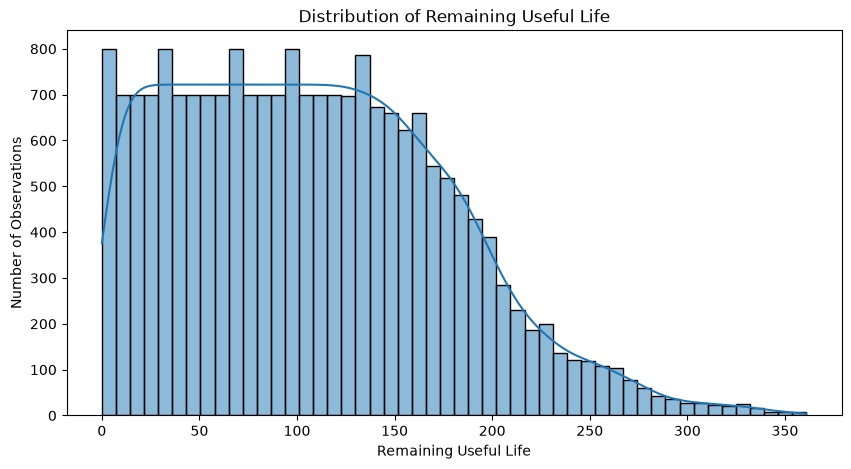

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(train["RUL"], bins=50, kde=True)

plt.xlabel("Remaining Useful Life")
plt.ylabel("Number of Observations")
plt.title("Distribution of Remaining Useful Life")

plt.show()

In [16]:
print(train["RUL"].describe())

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64


In [17]:
id="sensorset"
constant_sensors = low_variance.index.tolist()

useful_sensors = [
    sensor for sensor in sensor_columns
    if sensor not in constant_sensors
]

print("Removed sensors:", constant_sensors)
print("Useful sensors:", useful_sensors)
print("Number of useful sensors:", len(useful_sensors))

Removed sensors: ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_8', 'sensor_10', 'sensor_13', 'sensor_15', 'sensor_16', 'sensor_18', 'sensor_19']
Useful sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_14', 'sensor_17', 'sensor_20', 'sensor_21']
Number of useful sensors: 11


In [18]:
X = train[useful_sensors].copy()
y = train["RUL"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (20631, 11)
Target shape: (20631,)


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled feature shape:", X_scaled.shape)

Scaled feature shape: (20631, 11)


In [20]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

print("Explained variance by each component:")
print(explained_variance)

Explained variance by each component:
[0.6310534  0.16456424 0.03753393 0.03347182 0.03135828 0.02779281
 0.02348096 0.01851257 0.01613502 0.01342344 0.00267354]


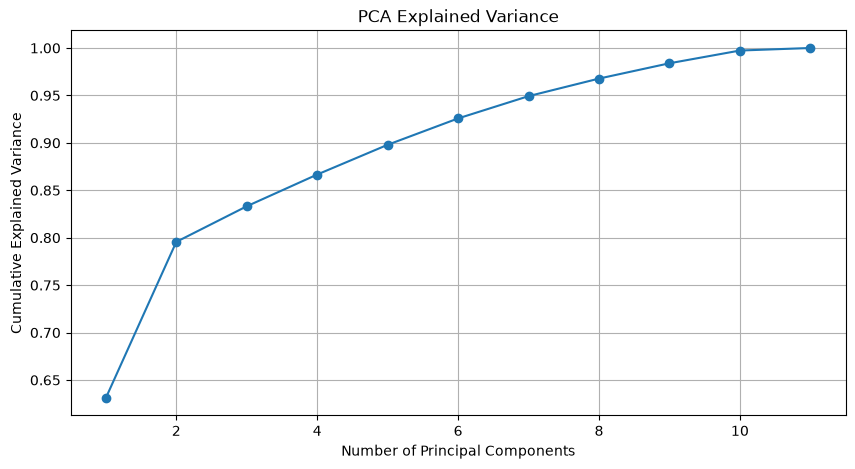

In [21]:
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")

plt.grid()
plt.show()

In [22]:
pca_7 = PCA(n_components=7)

X_pca_7 = pca_7.fit_transform(X_scaled)

print("Original feature shape:", X.shape)
print("PCA feature shape:", X_pca_7.shape)
print(
    "Variance retained:",
    pca_7.explained_variance_ratio_.sum()
)

Original feature shape: (20631, 11)
PCA feature shape: (20631, 7)
Variance retained: 0.9492554375482364


In [23]:
from sklearn.model_selection import train_test_split

engine_ids = train["engine_id"].unique()

train_engines, val_engines = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))

Training engines: 80
Validation engines: 20


In [24]:
train_data = train[train["engine_id"].isin(train_engines)].copy()
val_data = train[train["engine_id"].isin(val_engines)].copy()

print("Training rows:", len(train_data))
print("Validation rows:", len(val_data))

Training rows: 16561
Validation rows: 4070


In [25]:
X_train = train_data[useful_sensors]
y_train = train_data["RUL"]

X_val = val_data[useful_sensors]
y_val = val_data["RUL"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (16561, 11)
y_train: (16561,)
X_val: (4070, 11)
y_val: (4070,)


In [26]:
from sklearn.preprocessing import StandardScaler

scaler_model = StandardScaler()

X_train_scaled = scaler_model.fit_transform(X_train)
X_val_scaled = scaler_model.transform(X_val)

print("Training scaled:", X_train_scaled.shape)
print("Validation scaled:", X_val_scaled.shape)

Training scaled: (16561, 11)
Validation scaled: (4070, 11)


In [27]:
from sklearn.decomposition import PCA

pca_model = PCA(n_components=7)

X_train_pca = pca_model.fit_transform(X_train_scaled)
X_val_pca = pca_model.transform(X_val_scaled)

print("Training PCA:", X_train_pca.shape)
print("Validation PCA:", X_val_pca.shape)

print(
    "Variance retained:",
    pca_model.explained_variance_ratio_.sum()
)

Training PCA: (16561, 7)
Validation PCA: (4070, 7)
Variance retained: 0.948873631981838


In [28]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

knn_raw = KNeighborsRegressor(n_neighbors=5)

knn_raw.fit(X_train_scaled, y_train)

y_pred_knn_raw = knn_raw.predict(X_val_scaled)

mae_knn_raw = mean_absolute_error(y_val, y_pred_knn_raw)
rmse_knn_raw = np.sqrt(mean_squared_error(y_val, y_pred_knn_raw))
r2_knn_raw = r2_score(y_val, y_pred_knn_raw)

print("KNN - Original Sensors")
print("MAE :", mae_knn_raw)
print("RMSE:", rmse_knn_raw)
print("R²  :", r2_knn_raw)

KNN - Original Sensors
MAE : 28.827125307125307
RMSE: 39.507576109204294
R²  : 0.6378686724272019


In [29]:
knn_pca = KNeighborsRegressor(n_neighbors=5)

knn_pca.fit(X_train_pca, y_train)

y_pred_knn_pca = knn_pca.predict(X_val_pca)

mae_knn_pca = mean_absolute_error(y_val, y_pred_knn_pca)
rmse_knn_pca = np.sqrt(mean_squared_error(y_val, y_pred_knn_pca))
r2_knn_pca = r2_score(y_val, y_pred_knn_pca)

print("KNN + PCA")
print("MAE :", mae_knn_pca)
print("RMSE:", rmse_knn_pca)
print("R²  :", r2_knn_pca)

KNN + PCA
MAE : 28.91685503685504
RMSE: 39.7435931820111
R²  : 0.6335290252257115


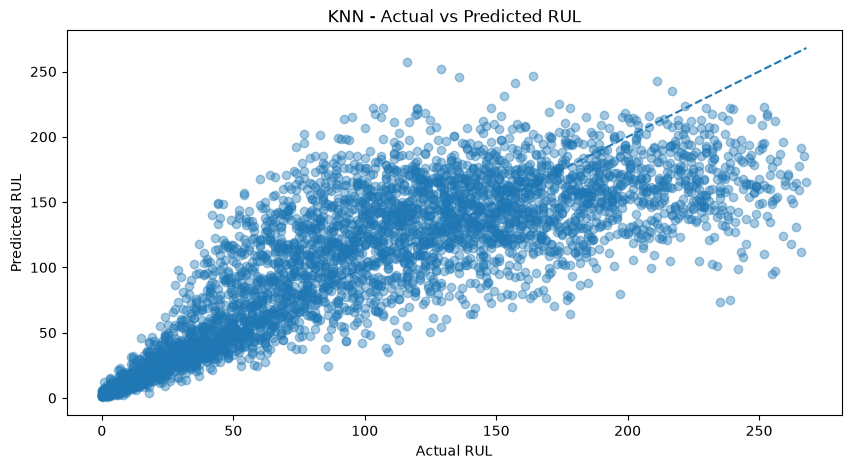

In [30]:
plt.figure(figsize=(10, 5))

plt.scatter(y_val, y_pred_knn_raw, alpha=0.4)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("KNN - Actual vs Predicted RUL")

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    linestyle="--"
)

plt.show()

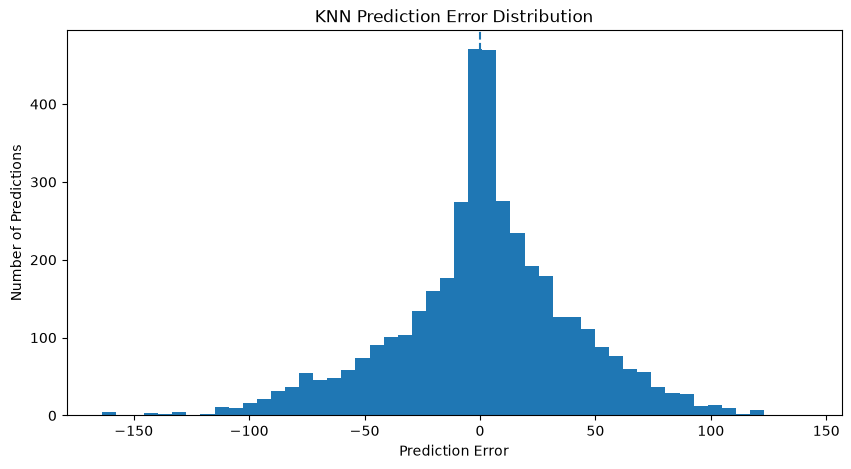

In [31]:
errors = y_pred_knn_raw - y_val

plt.figure(figsize=(10, 5))

plt.hist(errors, bins=50)

plt.xlabel("Prediction Error")
plt.ylabel("Number of Predictions")
plt.title("KNN Prediction Error Distribution")

plt.axvline(0, linestyle="--")

plt.show()

In [32]:
rf_pca = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_pca.fit(X_train_pca, y_train)

y_pred_rf_pca = rf_pca.predict(X_val_pca)

mae_rf_pca = mean_absolute_error(y_val, y_pred_rf_pca)
rmse_rf_pca = np.sqrt(mean_squared_error(y_val, y_pred_rf_pca))
r2_rf_pca = r2_score(y_val, y_pred_rf_pca)

print("Random Forest + PCA")
print("MAE :", mae_rf_pca)
print("RMSE:", rmse_rf_pca)
print("R²  :", r2_rf_pca)

NameError: name 'RandomForestRegressor' is not defined

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_raw = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_raw.fit(X_train_scaled, y_train)

y_pred_rf_raw = rf_raw.predict(X_val_scaled)

mae_rf_raw = mean_absolute_error(y_val, y_pred_rf_raw)
rmse_rf_raw = np.sqrt(mean_squared_error(y_val, y_pred_rf_raw))
r2_rf_raw = r2_score(y_val, y_pred_rf_raw)

print("Random Forest - Original Sensors")
print("MAE :", mae_rf_raw)
print("RMSE:", rmse_rf_raw)
print("R²  :", r2_rf_raw)

Random Forest - Original Sensors
MAE : 26.276267813267815
RMSE: 35.90328197922311
R²  : 0.7009294661938836


In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
n_estimators=100

In [ ]:
tree_results = []

for n in [50, 100, 200]:

    model = RandomForestRegressor(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_val_scaled)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    tree_results.append([n, mae, rmse, r2])

tree_results

[[50, 26.49310565110565, np.float64(36.21679956745337), 0.6956835246769544],
 [100, 26.276267813267815, np.float64(35.90328197922311), 0.7009294661938836],
 [200, 26.191272727272725, np.float64(35.7520886975962), 0.7034430106239155]]

In [ ]:
tree_results_df = pd.DataFrame(
    tree_results,
    columns=["Trees", "MAE", "RMSE", "R2"]
)

print(tree_results_df)

   Trees        MAE       RMSE        R2
0     50  26.493106  36.216800  0.695684
1    100  26.276268  35.903282  0.700929
2    200  26.191273  35.752089  0.703443


In [ ]:
y_train_capped = y_train.clip(upper=125)
y_val_capped = y_val.clip(upper=125)

rf_capped = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_capped.fit(X_train_scaled, y_train_capped)

y_pred_capped = rf_capped.predict(X_val_scaled)

mae_capped = mean_absolute_error(y_val_capped, y_pred_capped)
rmse_capped = np.sqrt(
    mean_squared_error(y_val_capped, y_pred_capped)
)
r2_capped = r2_score(y_val_capped, y_pred_capped)

print("Random Forest + RUL Capping")
print("MAE :", mae_capped)
print("RMSE:", rmse_capped)
print("R²  :", r2_capped)

Random Forest + RUL Capping
MAE : 12.726760442260444
RMSE: 17.446373942126232
R²  : 0.8250910014399673


In [ ]:
low_rul_mask = y_val <= 50

low_rul_actual = y_val[low_rul_mask]
low_rul_pred = y_pred_capped[low_rul_mask]

low_rul_mae = mean_absolute_error(
    low_rul_actual,
    low_rul_pred
)

low_rul_rmse = np.sqrt(
    mean_squared_error(
        low_rul_actual,
        low_rul_pred
    )
)

print("Low-RUL Performance (Actual RUL <= 50)")
print("Number of samples:", low_rul_mask.sum())
print("MAE :", low_rul_mae)
print("RMSE:", low_rul_rmse)

Low-RUL Performance (Actual RUL <= 50)
Number of samples: 1020
MAE : 10.11828431372549
RMSE: 15.734559390579905


In [ ]:
from sklearn.ensemble import IsolationForest

healthy_data = train_data[train_data["RUL"] >= 100]

X_healthy = healthy_data[useful_sensors]

print("Healthy reference samples:", len(X_healthy))

Healthy reference samples: 8561


In [ ]:
X_healthy_scaled = scaler_model.transform(X_healthy)

print("Healthy scaled shape:", X_healthy_scaled.shape)

Healthy scaled shape: (8561, 11)


In [ ]:
isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

isolation_forest.fit(X_healthy_scaled)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",200
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [ ]:
X_val_anomaly = scaler_model.transform(
    val_data[useful_sensors]
)

anomaly_predictions = isolation_forest.predict(
    X_val_anomaly
)

anomaly_scores = isolation_forest.decision_function(
    X_val_anomaly
)

val_data["anomaly"] = anomaly_predictions
val_data["anomaly_score"] = anomaly_scores

print(val_data["anomaly"].value_counts())

anomaly
 1    2650
-1    1420
Name: count, dtype: int64


In [ ]:
val_data["RUL_group"] = pd.cut(
    val_data["RUL"],
    bins=[-1, 50, 100, 150, float("inf")],
    labels=["0-50", "51-100", "101-150", ">150"]
)

anomaly_rate = (
    val_data.groupby("RUL_group", observed=False)["anomaly"]
    .apply(lambda x: (x == -1).mean() * 100)
)

print("Anomaly rate by RUL group:")
print(anomaly_rate)

Anomaly rate by RUL group:
RUL_group
0-50       93.921569
51-100     34.000000
101-150     5.792683
>150        6.097561
Name: anomaly, dtype: float64


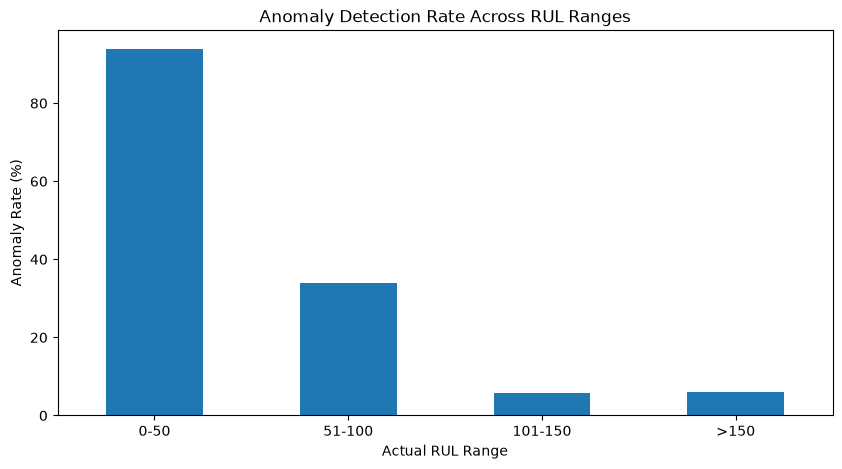

In [ ]:
plt.figure(figsize=(10, 5))

anomaly_rate.plot(kind="bar")

plt.xlabel("Actual RUL Range")
plt.ylabel("Anomaly Rate (%)")
plt.title("Anomaly Detection Rate Across RUL Ranges")

plt.xticks(rotation=0)
plt.show()

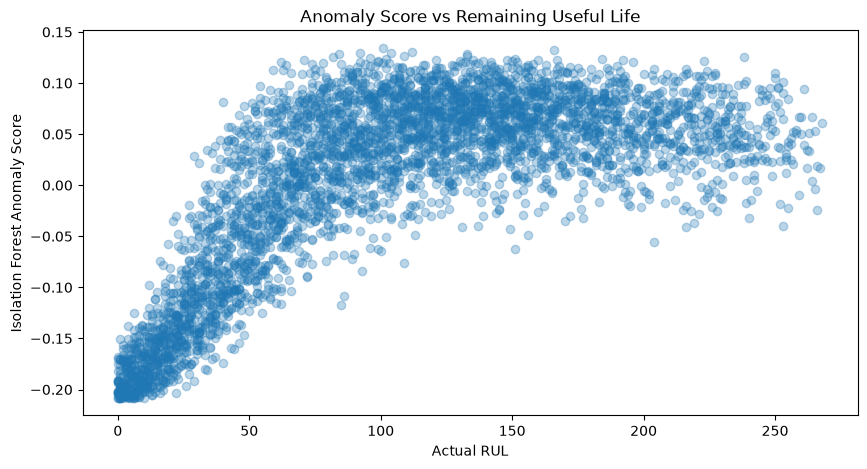

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    val_data["RUL"],
    val_data["anomaly_score"],
    alpha=0.3
)

plt.xlabel("Actual RUL")
plt.ylabel("Isolation Forest Anomaly Score")
plt.title("Anomaly Score vs Remaining Useful Life")

plt.show()

In [ ]:
healthy_scores = isolation_forest.decision_function(
    X_healthy_scaled
)

healthy_low = np.percentile(healthy_scores, 5)
healthy_high = np.percentile(healthy_scores, 95)

print("Healthy score range:")
print("5th percentile :", healthy_low)
print("95th percentile:", healthy_high)

Healthy score range:
5th percentile : 0.0
95th percentile: 0.11144243950238564


In [ ]:
val_data["health_score"] = (
    (val_data["anomaly_score"] - healthy_low)
    / (healthy_high - healthy_low)
    * 100
)

val_data["health_score"] = val_data["health_score"].clip(0, 100)

print(
    val_data[
        ["RUL", "anomaly_score", "health_score"]
    ].head(10)
)

     RUL  anomaly_score  health_score
0  191.0       0.072141     64.734039
1  190.0       0.080850     72.548806
2  189.0       0.063999     57.428143
3  188.0       0.053481     47.989874
4  187.0       0.113106    100.000000
5  186.0       0.070823     63.551391
6  185.0       0.090675     81.365320
7  184.0       0.055143     49.481323
8  183.0       0.039586     35.521453
9  182.0       0.024305     21.809283


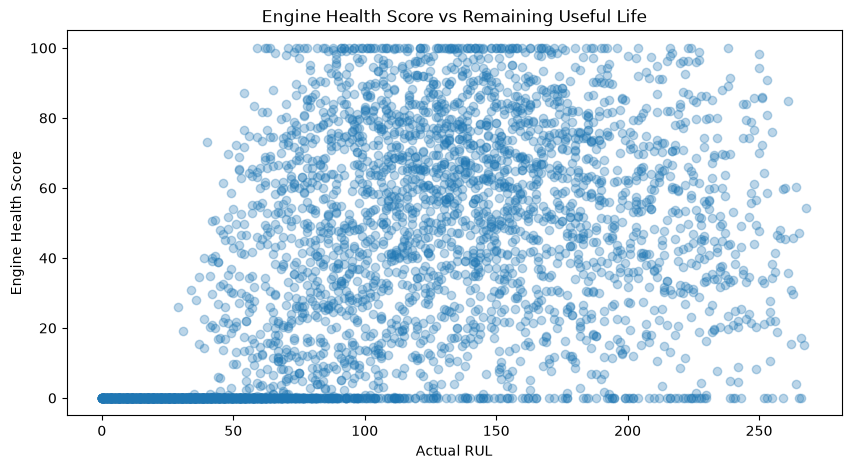

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    val_data["RUL"],
    val_data["health_score"],
    alpha=0.3
)

plt.xlabel("Actual RUL")
plt.ylabel("Engine Health Score")
plt.title("Engine Health Score vs Remaining Useful Life")

plt.show()

In [ ]:
health_by_rul = (
    val_data.groupby("RUL_group", observed=False)["health_score"]
    .agg(["mean", "median"])
)

print(health_by_rul)

                mean     median
RUL_group                      
0-50        1.746353   0.000000
51-100     31.134604  22.380562
101-150    55.377617  59.045552
>150       52.135349  53.828245


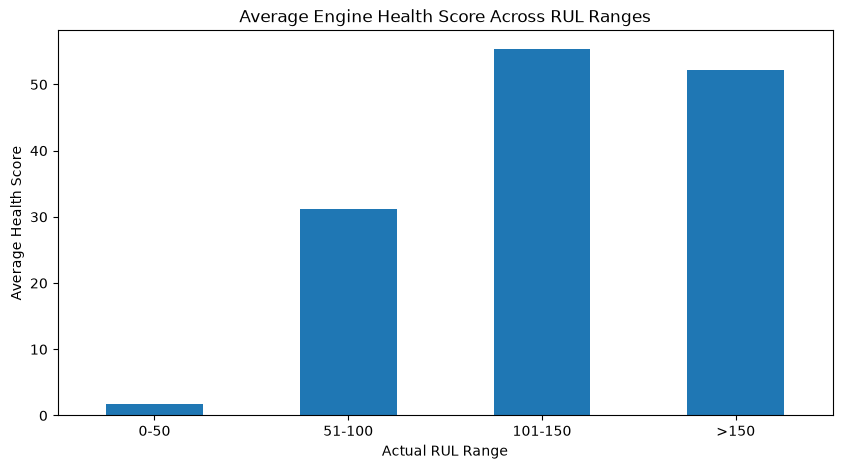

In [ ]:
plt.figure(figsize=(10, 5))

health_by_rul["mean"].plot(
    kind="bar"
)

plt.xlabel("Actual RUL Range")
plt.ylabel("Average Health Score")
plt.title("Average Engine Health Score Across RUL Ranges")

plt.xticks(rotation=0)
plt.show()


In [ ]:
results = pd.DataFrame([
    ["KNN", "Original Sensors", 28.83, 39.51, 0.638],
    ["KNN", "PCA (7 Components)", 28.92, 39.74, 0.634],
    ["Random Forest", "Original Sensors", 26.28, 35.90, 0.701],
    ["Random Forest", "PCA (7 Components)", 26.77, 36.92, 0.684],
    ["Random Forest (200 trees)", "Original Sensors", 26.19, 35.75, 0.703],
    ["Random Forest + RUL Capping", "Original Sensors", 12.73, 17.45, 0.825]
], columns=["Model", "Features", "MAE", "RMSE", "R2"])

print(results)

                         Model            Features    MAE   RMSE     R2
0                          KNN    Original Sensors  28.83  39.51  0.638
1                          KNN  PCA (7 Components)  28.92  39.74  0.634
2                Random Forest    Original Sensors  26.28  35.90  0.701
3                Random Forest  PCA (7 Components)  26.77  36.92  0.684
4    Random Forest (200 trees)    Original Sensors  26.19  35.75  0.703
5  Random Forest + RUL Capping    Original Sensors  12.73  17.45  0.825


# Key Findings

- 11 useful sensor features were selected after removing near-constant sensors.
- PCA reduced the 11 sensor features to 7 components while retaining approximately 94.9% variance.
- PCA did not improve KNN or Random Forest performance on the validation engines.
- Random Forest performed better than KNN for RUL prediction.
- Increasing Random Forest trees from 100 to 200 produced a small improvement.
- Capping RUL at 125 significantly improved performance on the capped prediction task.
- The capped Random Forest achieved MAE = 12.73 cycles, RMSE = 17.45 cycles, and R² = 0.825.
- For observations with actual RUL ≤ 50, the capped model achieved MAE = 10.12 cycles.
- Isolation Forest detected anomalies in 93.92% of observations with RUL ≤ 50.
- Anomaly rates increased substantially as engines approached failure.
- The Isolation Forest anomaly score showed a strong relationship with engine degradation.

In [ ]:
print("train:", "train" in globals())
print("useful_sensors:", "useful_sensors" in globals())
print("scaler_model:", "scaler_model" in globals())
print("rf_capped:", "rf_capped" in globals())
print("X_train_scaled:", "X_train_scaled" in globals())
print("y_train_capped:", "y_train_capped" in globals())

train: True
useful_sensors: True
scaler_model: True
rf_capped: True
X_train_scaled: True
y_train_capped: True


In [ ]:
test_path = "../data/test_FD001.txt"

test = pd.read_csv(
    test_path,
    sep=r"\s+",
    header=None
)

test.columns = columns

print("Test shape:", test.shape)
print("Number of test engines:", test["engine_id"].nunique())

Test shape: (13096, 26)
Number of test engines: 100


In [ ]:
# Load the true RUL values for the test engines

rul_path = "../data/RUL_FD001.txt"

test_rul = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None
)

test_rul = test_rul.iloc[:, 0].values

print("Number of RUL values:", len(test_rul))
print("First 5 RUL values:", test_rul[:5])

Number of RUL values: 100
First 5 RUL values: [112  98  69  82  91]


In [ ]:
# Maximum observed cycle for each test engine
test_max_cycles = test.groupby("engine_id")["cycle"].max()

# Calculate RUL for every observation
test["RUL"] = test.apply(
    lambda row:
        test_rul[int(row["engine_id"]) - 1]
        + test_max_cycles[row["engine_id"]]
        - row["cycle"],
    axis=1
)

print(test[["engine_id", "cycle", "RUL"]].head(10))

   engine_id  cycle    RUL
0          1      1  142.0
1          1      2  141.0
2          1      3  140.0
3          1      4  139.0
4          1      5  138.0
5          1      6  137.0
6          1      7  136.0
7          1      8  135.0
8          1      9  134.0
9          1     10  133.0


In [ ]:
print(test["RUL"].describe())
print("\nRUL range:",
      test["RUL"].min(),
      "to",
      test["RUL"].max())

count    13096.000000
mean       141.238470
std         58.980114
min          7.000000
25%        102.000000
50%        140.000000
75%        179.000000
max        340.000000
Name: RUL, dtype: float64

RUL range: 7.0 to 340.0


In [ ]:
X_test = test[useful_sensors]

X_test_scaled = scaler_model.transform(X_test)

print("Test feature shape:", X_test.shape)
print("Test scaled shape:", X_test_scaled.shape)

Test feature shape: (13096, 11)
Test scaled shape: (13096, 11)


In [ ]:
y_pred_test = rf_capped.predict(X_test_scaled)

print("Predictions generated:", len(y_pred_test))
print("First 10 predictions:")
print(y_pred_test[:10])

Predictions generated: 13096
First 10 predictions:
[119.735 111.51  115.79  120.655 121.315 122.185 121.55  118.075 107.915
 123.48 ]


In [ ]:
# Get the final observed cycle for each test engine
test_last = (
    test.sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .sort_values("engine_id")
)

# Get the corresponding predictions
final_predictions = y_pred_test[test_last.index]

# True RUL from RUL_FD001
final_actual_rul = test_rul

print("Number of test engines:", len(test_last))
print("Number of predictions:", len(final_predictions))

print("\nFirst 10 actual RUL values:")
print(final_actual_rul[:10])

print("\nFirst 10 predicted RUL values:")
print(final_predictions[:10])

Number of test engines: 100
Number of predictions: 100

First 10 actual RUL values:
[112  98  69  82  91  93  91  95 111  96]

First 10 predicted RUL values:
[116.62  117.94   58.37   97.275  99.5   110.06  103.615 102.175 107.28
 102.715]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

final_actual_capped = np.clip(final_actual_rul, 0, 125)

mae_test = mean_absolute_error(
    final_actual_capped,
    final_predictions
)

rmse_test = np.sqrt(
    mean_squared_error(
        final_actual_capped,
        final_predictions
    )
)

r2_test = r2_score(
    final_actual_capped,
    final_predictions
)

print("FINAL TEST PERFORMANCE - RUL CAPPED AT 125")
print("MAE :", mae_test)
print("RMSE:", rmse_test)
print("R²  :", r2_test)

FINAL TEST PERFORMANCE - RUL CAPPED AT 125
MAE : 11.92245
RMSE: 17.396996472092532
R²  : 0.8115314705291689


In [ ]:
# Predict RUL on the unseen test engines using the uncapped Random Forest

y_pred_test_raw = rf_raw.predict(X_test_scaled)

final_predictions_raw = y_pred_test_raw[test_last.index]

mae_test_raw = mean_absolute_error(
    final_actual_rul,
    final_predictions_raw
)

rmse_test_raw = np.sqrt(
    mean_squared_error(
        final_actual_rul,
        final_predictions_raw
    )
)

r2_test_raw = r2_score(
    final_actual_rul,
    final_predictions_raw
)

print("FINAL TEST PERFORMANCE - UNCAPPED RUL")
print("MAE :", mae_test_raw)
print("RMSE:", rmse_test_raw)
print("R²  :", r2_test_raw)

FINAL TEST PERFORMANCE - UNCAPPED RUL
MAE : 24.801200000000005
RMSE: 34.04874605620595
R²  : 0.3286597274050106


In [ ]:
final_results = pd.DataFrame([
    ["KNN", "Original Sensors", 28.83, 39.51, 0.638],
    ["KNN", "PCA (7 Components)", 28.92, 39.74, 0.634],
    ["Random Forest", "Original Sensors", 26.28, 35.90, 0.701],
    ["Random Forest", "PCA (7 Components)", 26.77, 36.92, 0.684],
    ["Random Forest (200 Trees)", "Original Sensors", 26.19, 35.75, 0.703],
    ["Random Forest + RUL Cap 125", "Original Sensors", 12.73, 17.45, 0.825],
    ["Final Test - Uncapped RF", "Original Sensors", 24.80, 34.05, 0.329],
    ["Final Test - Capped RF", "Original Sensors", 11.92, 17.40, 0.812]
], columns=["Model", "Features", "MAE", "RMSE", "R2"])

final_results

,Model,Features,MAE,RMSE,R2
0,KNN,Original Sensors,28.83,39.51,0.638
1,KNN,PCA (7 Components),28.92,39.74,0.634
2,Random Forest,Original Sensors,26.28,35.90,0.701
3,Random Forest,PCA (7 Components),26.77,36.92,0.684
4,Random Forest (200 Trees),Original Sensors,26.19,35.75,0.703
5,Random Forest + RUL Cap 125,Original Sensors,12.73,17.45,0.825
6,Final Test - Uncapped RF,Original Sensors,24.80,34.05,0.329
7,Final Test - Capped RF,Original Sensors,11.92,17.40,0.812


## Final Model Selection

The Random Forest model with 200 trees and a capped RUL target (maximum RUL = 125 cycles) was selected as the final RUL prediction model.

On the unseen C-MAPSS FD001 test engines, the model achieved:

- MAE: 11.92 cycles
- RMSE: 17.40 cycles
- R²: 0.812

RUL capping substantially improved performance compared with predicting the full uncapped RUL range.

Isolation Forest was additionally used for anomaly detection. The anomaly rate increased strongly as RUL decreased, reaching 93.92% for observations with RUL ≤ 50.

In [33]:
print("test:", "test" in globals())
print("test_rul:", "test_rul" in globals())
print("rf_capped:", "rf_capped" in globals())
print("isolation_forest:", "isolation_forest" in globals())
print("val_data:", "val_data" in globals())

test: False
test_rul: False
rf_capped: False
isolation_forest: False
val_data: True


In [38]:
rf_capped = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_capped.fit(X_train_scaled, y_train_capped)

y_pred_capped = rf_capped.predict(X_val_scaled)

In [35]:
from sklearn.ensemble import RandomForestRegressor

In [37]:
y_train_capped = y_train.clip(upper=125)

In [39]:
print("y_train_capped:", "y_train_capped" in globals())
print("rf_capped:", "rf_capped" in globals())

y_train_capped: True
rf_capped: True


In [40]:
from sklearn.ensemble import IsolationForest

healthy_data = train_data[train_data["RUL"] >= 100]

X_healthy = healthy_data[useful_sensors]
X_healthy_scaled = scaler_model.transform(X_healthy)

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

isolation_forest.fit(X_healthy_scaled)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",200
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.05
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [41]:
X_val_anomaly = scaler_model.transform(val_data[useful_sensors])

anomaly_predictions = isolation_forest.predict(X_val_anomaly)
anomaly_scores = isolation_forest.decision_function(X_val_anomaly)

val_data["anomaly"] = anomaly_predictions
val_data["anomaly_score"] = anomaly_scores

In [42]:
print("isolation_forest:", "isolation_forest" in globals())

isolation_forest: True


In [43]:
test_path = "../data/test_FD001.txt"

test = pd.read_csv(
    test_path,
    sep=r"\s+",
    header=None
)

test.columns = columns

In [44]:
rul_path = "../data/RUL_FD001.txt"

test_rul = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None
)

test_rul = test_rul.iloc[:, 0].values

In [45]:
test_max_cycles = test.groupby("engine_id")["cycle"].max()

test["RUL"] = test.apply(
    lambda row:
        test_rul[int(row["engine_id"]) - 1]
        + test_max_cycles[row["engine_id"]]
        - row["cycle"],
    axis=1
)

In [46]:
X_test = test[useful_sensors]

X_test_scaled = scaler_model.transform(X_test)

y_pred_test = rf_capped.predict(X_test_scaled)

In [47]:
test_last = (
    test.sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .sort_values("engine_id")
)

final_predictions = y_pred_test[test_last.index]
final_actual_rul = test_rul

In [48]:
final_actual_capped = np.clip(final_actual_rul, 0, 125)

mae_test = mean_absolute_error(
    final_actual_capped,
    final_predictions
)

rmse_test = np.sqrt(
    mean_squared_error(
        final_actual_capped,
        final_predictions
    )
)

r2_test = r2_score(
    final_actual_capped,
    final_predictions
)

print("Test MAE:", round(mae_test, 2))
print("Test RMSE:", round(rmse_test, 2))
print("Test R²:", round(r2_test, 3))

Test MAE: 11.92
Test RMSE: 17.4
Test R²: 0.812


In [49]:
val_warning = val_data.sort_values(
    ["engine_id", "cycle"]
).copy()

In [50]:
val_warning["anomaly_flag"] = (
    val_warning["anomaly"] == -1
).astype(int)

val_warning["anomaly_streak"] = (
    val_warning
    .groupby("engine_id")["anomaly_flag"]
    .rolling(window=3, min_periods=3)
    .sum()
    .reset_index(level=0, drop=True)
)

val_warning["sustained_anomaly"] = (
    val_warning["anomaly_streak"] >= 3
)

In [51]:
critical_cycles = (
    val_warning[val_warning["RUL"] <= 50]
    .groupby("engine_id")["cycle"]
    .min()
)

In [52]:
warning_cycles = (
    val_warning[val_warning["sustained_anomaly"]]
    .groupby("engine_id")["cycle"]
    .min()
)

In [53]:
lead_time_results = pd.DataFrame({
    "critical_cycle": critical_cycles,
    "warning_cycle": warning_cycles
})

lead_time_results["lead_time"] = (
    lead_time_results["critical_cycle"]
    - lead_time_results["warning_cycle"]
)

In [54]:
lead_time_results.head(10)

,critical_cycle,warning_cycle,lead_time
engine_id,,,
1,142,152,-10
5,219,182,37
11,190,183,7
13,113,105,8
19,108,85,23
23,118,102,16
31,184,196,-12
32,141,105,36
34,145,129,16


In [55]:
print("Validation engines:", len(critical_cycles))
print("Engines with warning:", len(warning_cycles))
print()
print(lead_time_results["lead_time"].describe())

Validation engines: 20
Engines with warning: 20

count     20.000000
mean      23.550000
std       43.537612
min      -17.000000
25%        2.750000
50%       14.500000
75%       33.000000
max      177.000000
Name: lead_time, dtype: float64


In [56]:
lead_time_results

,critical_cycle,warning_cycle,lead_time
engine_id,,,
1,142,152,-10
5,219,182,37
11,190,183,7
13,113,105,8
19,108,85,23
23,118,102,16
31,184,196,-12
32,141,105,36
34,145,129,16


In [57]:
positive_lead_times = lead_time_results[
    lead_time_results["lead_time"] > 0
]["lead_time"]

late_warnings = lead_time_results[
    lead_time_results["lead_time"] <= 0
]["lead_time"]

print("Total validation engines:", len(lead_time_results))
print("Early warnings:", len(positive_lead_times))
print("Late/no early warning:", len(late_warnings))

print()
print("Early warning coverage:",
      round(len(positive_lead_times) / len(lead_time_results) * 100, 2), "%")

print()
print("Positive lead time statistics:")
print(positive_lead_times.describe())

Total validation engines: 20
Early warnings: 15
Late/no early warning: 5

Early warning coverage: 75.0 %

Positive lead time statistics:
count     15.000000
mean      35.733333
std       43.976401
min        7.000000
25%       11.500000
50%       23.000000
75%       36.000000
max      177.000000
Name: lead_time, dtype: float64


In [58]:
lead_time_results.sort_values(
    "lead_time",
    ascending=False
).head(5)

,critical_cycle,warning_cycle,lead_time
engine_id,,,
78,181,4,177
84,217,130,87
5,219,182,37
32,141,105,36
40,138,102,36


In [59]:
val_warning[
    (val_warning["engine_id"] == 78)
][
    ["engine_id", "cycle", "RUL", "anomaly", "anomaly_score", "sustained_anomaly"]
].head(30)

,engine_id,cycle,RUL,anomaly,anomaly_score,sustained_anomaly
15523,78,1,230.0,1,0.000937,False
15524,78,2,229.0,-1,-0.012359,False
15525,78,3,228.0,-1,-0.025195,False
15526,78,4,227.0,-1,-0.006967,True
15527,78,5,226.0,-1,-0.021771,True
15528,78,6,225.0,-1,-0.007314,True
15529,78,7,224.0,1,0.064714,False
15530,78,8,223.0,-1,-0.014532,False
15531,78,9,222.0,1,0.012822,False
15532,78,10,221.0,1,0.079051,False


In [60]:
val_warning["anomaly_rate_10"] = (
    val_warning
    .groupby("engine_id")["anomaly_flag"]
    .rolling(window=10, min_periods=10)
    .mean()
    .reset_index(level=0, drop=True)
)

In [61]:
val_warning["persistent_warning"] = (
    val_warning["anomaly_rate_10"] >= 0.6
)

In [63]:
persistent_warning_cycles = (
    val_warning[val_warning["persistent_warning"]]
    .groupby("engine_id")["cycle"]
    .min()
)

In [64]:
persistent_results = pd.DataFrame({
    "critical_cycle": critical_cycles,
    "warning_cycle": persistent_warning_cycles
})

persistent_results["lead_time"] = (
    persistent_results["critical_cycle"]
    - persistent_results["warning_cycle"]
)

In [ ]:
print("Validation engines:", len(persistent_results))
print("Engines with persistent warning:", len(persistent_warning_cycles))

print()
print(persistent_results["lead_time"].describe())

In [65]:
persistent_results.sort_values(
    "lead_time",
    ascending=False
).head(10)

,critical_cycle,warning_cycle,lead_time
engine_id,,,
78,181,10,171
84,217,156,61
40,138,103,35
5,219,188,31
19,108,81,27
91,85,59,26
34,145,129,16
81,190,179,11
32,141,131,10


In [66]:
print("Total validation engines:", len(persistent_results))
print(
    "Engines with persistent warning:",
    persistent_results["warning_cycle"].notna().sum()
)

valid_leads = persistent_results[
    persistent_results["lead_time"].notna()
]["lead_time"]

positive_leads = valid_leads[valid_leads > 0]

print()
print("Early warnings:", len(positive_leads))
print(
    "Early warning coverage:",
    round(
        len(positive_leads) / len(persistent_results) * 100,
        2
    ),
    "%"
)

print()
print("Lead-time statistics:")
print(positive_leads.describe())

Total validation engines: 20
Engines with persistent warning: 20

Early warnings: 15
Early warning coverage: 75.0 %

Lead-time statistics:
count     15.000000
mean      28.333333
std       42.478006
min        2.000000
25%        8.000000
50%       11.000000
75%       29.000000
max      171.000000
Name: lead_time, dtype: float64


In [67]:
val_warning[
    (val_warning["engine_id"] == 78) &
    (val_warning["cycle"] <= 40)
][[
    "cycle",
    "RUL",
    "anomaly",
    "anomaly_score",
    "anomaly_rate_10",
    "persistent_warning"
]]

,cycle,RUL,anomaly,anomaly_score,anomaly_rate_10,persistent_warning
15523,1,230.0,1,0.000937,NaN,False
15524,2,229.0,-1,-0.012359,NaN,False
15525,3,228.0,-1,-0.025195,NaN,False
15526,4,227.0,-1,-0.006967,NaN,False
15527,5,226.0,-1,-0.021771,NaN,False
15528,6,225.0,-1,-0.007314,NaN,False
15529,7,224.0,1,0.064714,NaN,False
15530,8,223.0,-1,-0.014532,NaN,False
15531,9,222.0,1,0.012822,NaN,False
15532,10,221.0,1,0.079051,0.6,True


In [68]:
val_warning["persistent_warning_70"] = (
    val_warning["anomaly_rate_10"] >= 0.7
)

In [69]:
warning_cycles_70 = (
    val_warning[val_warning["persistent_warning_70"]]
    .groupby("engine_id")["cycle"]
    .min()
)

In [70]:
results_70 = pd.DataFrame({
    "critical_cycle": critical_cycles,
    "warning_cycle": warning_cycles_70
})

results_70["lead_time"] = (
    results_70["critical_cycle"]
    - results_70["warning_cycle"]
)

In [71]:
valid_leads_70 = results_70[
    results_70["lead_time"].notna()
]["lead_time"]

positive_leads_70 = valid_leads_70[
    valid_leads_70 > 0
]

print("Validation engines:", len(results_70))
print("Engines with warning:", len(warning_cycles_70))
print("Early warnings:", len(positive_leads_70))

print(
    "Early warning coverage:",
    round(
        len(positive_leads_70) / len(results_70) * 100,
        2
    ),
    "%"
)

print()
print("Lead-time statistics:")
print(positive_leads_70.describe())

Validation engines: 20
Engines with warning: 20
Early warnings: 12
Early warning coverage: 60.0 %

Lead-time statistics:
count    12.000000
mean     18.916667
std      16.019638
min       5.000000
25%       7.750000
50%      12.000000
75%      25.500000
max      60.000000
Name: lead_time, dtype: float64


In [72]:
results_70.sort_values(
    "lead_time",
    ascending=False
).head(10)

,critical_cycle,warning_cycle,lead_time
engine_id,,,
84,217,157,60
40,138,107,31
5,219,189,30
91,85,61,24
19,108,85,23
34,145,131,14
81,190,180,10
32,141,132,9
54,207,199,8


In [73]:
print("Validation engines:", len(results_70))
print("Engines with warning:", len(warning_cycles_70))

valid_leads_70 = results_70[
    results_70["lead_time"].notna()
]["lead_time"]

positive_leads_70 = valid_leads_70[
    valid_leads_70 > 0
]

print("Early warnings:", len(positive_leads_70))

print(
    "Early warning coverage:",
    round(
        len(positive_leads_70) / len(results_70) * 100,
        2
    ),
    "%"
)

print()
print("Positive lead-time statistics:")
print(positive_leads_70.describe())

Validation engines: 20
Engines with warning: 20
Early warnings: 12
Early warning coverage: 60.0 %

Positive lead-time statistics:
count    12.000000
mean     18.916667
std      16.019638
min       5.000000
25%       7.750000
50%      12.000000
75%      25.500000
max      60.000000
Name: lead_time, dtype: float64


In [74]:
test_anomaly_predictions = isolation_forest.predict(
    X_test_scaled
)

test_anomaly_scores = isolation_forest.decision_function(
    X_test_scaled
)

test_warning = test.copy()

test_warning["anomaly"] = test_anomaly_predictions
test_warning["anomaly_score"] = test_anomaly_scores

In [75]:
test_warning["anomaly_flag"] = (
    test_warning["anomaly"] == -1
).astype(int)

test_warning["anomaly_rate_10"] = (
    test_warning
    .groupby("engine_id")["anomaly_flag"]
    .rolling(window=10, min_periods=10)
    .mean()
    .reset_index(level=0, drop=True)
)

In [76]:
test_warning["persistent_warning"] = (
    test_warning["anomaly_rate_10"] >= 0.7
)

In [77]:
test_warning_cycles = (
    test_warning[
        test_warning["persistent_warning"]
    ]
    .groupby("engine_id")["cycle"]
    .min()
)

In [78]:
print(
    "Test engines with warning:",
    len(test_warning_cycles)
)

Test engines with warning: 35


In [79]:
test_warning_summary = pd.DataFrame({
    "warning_cycle": test_warning_cycles,
    "final_rul": test_rul[test_warning_cycles.index - 1]
})

test_warning_summary["cycles_from_warning_to_final"] = (
    test.groupby("engine_id")["cycle"].max()
    .loc[test_warning_summary.index]
    - test_warning_summary["warning_cycle"]
)

test_warning_summary.sort_values(
    "cycles_from_warning_to_final",
    ascending=False
).head(10)

,warning_cycle,final_rul,cycles_from_warning_to_final
engine_id,,,
52,10,29,179
54,16,97,105
91,152,38,82
92,78,20,72
56,66,15,70
35,136,11,62
24,135,20,51
93,200,85,44
81,170,8,43


In [80]:
print("Test engines:", len(test_rul))
print("Engines with warning:", len(test_warning_summary))
print(
    "Warning rate:",
    round(len(test_warning_summary) / len(test_rul) * 100, 2),
    "%"
)

print()
print(
    test_warning_summary["cycles_from_warning_to_final"].describe()
)

Test engines: 100
Engines with warning: 35
Warning rate: 35.0 %

count     35.000000
mean      35.971429
std       35.049113
min        0.000000
25%       14.000000
50%       29.000000
75%       43.000000
max      179.000000
Name: cycles_from_warning_to_final, dtype: float64


In [81]:
engine_id = 5

engine_plot = val_warning[
    val_warning["engine_id"] == engine_id
].sort_values("cycle")

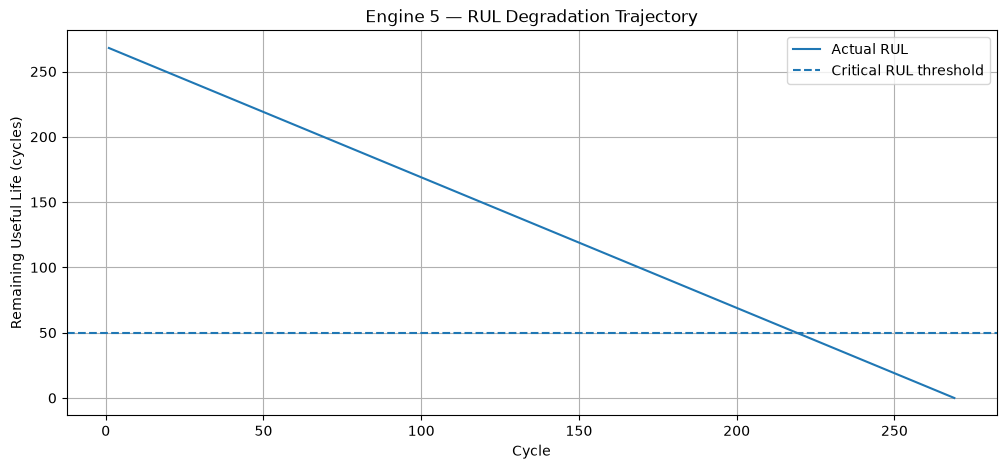

In [82]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    engine_plot["cycle"],
    engine_plot["RUL"],
    label="Actual RUL"
)

plt.axhline(
    50,
    linestyle="--",
    label="Critical RUL threshold"
)

plt.xlabel("Cycle")
plt.ylabel("Remaining Useful Life (cycles)")
plt.title(f"Engine {engine_id} — RUL Degradation Trajectory")
plt.legend()
plt.grid(True)

plt.show()

In [83]:
warning_cycle = results_70.loc[engine_id, "warning_cycle"]
critical_cycle = results_70.loc[engine_id, "critical_cycle"]

print("Warning cycle:", warning_cycle)
print("Critical cycle:", critical_cycle)
print("Lead time:", critical_cycle - warning_cycle, "cycles")

Warning cycle: 189
Critical cycle: 219
Lead time: 30 cycles


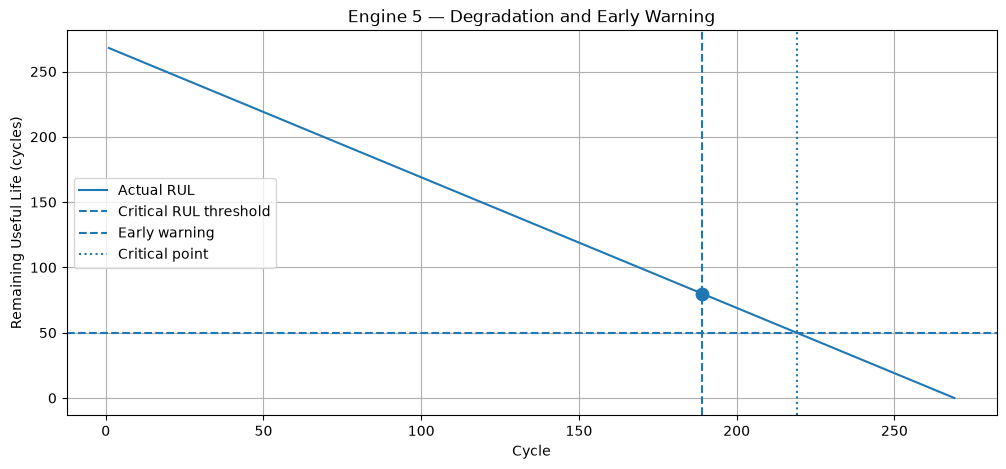

In [84]:
plt.figure(figsize=(12, 5))

plt.plot(
    engine_plot["cycle"],
    engine_plot["RUL"],
    label="Actual RUL"
)

plt.axhline(
    50,
    linestyle="--",
    label="Critical RUL threshold"
)

plt.axvline(
    warning_cycle,
    linestyle="--",
    label="Early warning"
)

plt.axvline(
    critical_cycle,
    linestyle=":",
    label="Critical point"
)

plt.scatter(
    warning_cycle,
    engine_plot.loc[
        engine_plot["cycle"] == warning_cycle,
        "RUL"
    ].iloc[0],
    s=80,
    zorder=5
)

plt.xlabel("Cycle")
plt.ylabel("Remaining Useful Life (cycles)")
plt.title(
    f"Engine {engine_id} — Degradation and Early Warning"
)

plt.legend()
plt.grid(True)

plt.show()

In [85]:
label="Early degradation warning"

In [86]:
label="Critical degradation onset"

In [87]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    rf_capped,
    "../models/rf_rul_model.pkl"
)

joblib.dump(
    isolation_forest,
    "../models/isolation_forest.pkl"
)

joblib.dump(
    scaler_model,
    "../models/scaler.pkl"
)

joblib.dump(
    useful_sensors,
    "../models/useful_sensors.pkl"
)

print("Models saved successfully!")

Models saved successfully!


In [88]:
print(os.listdir("../models"))

['isolation_forest.pkl', 'rf_rul_model.pkl', 'scaler.pkl', 'useful_sensors.pkl']


In [89]:
test_warning_cycles.index.tolist()[:10]

[3, 11, 17, 20, 24, 31, 32, 34, 35, 36]